<a href="https://colab.research.google.com/github/DianaBarradasSanchez/Simulaci-n-ll/blob/main/Metropolis_Hastings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelado Epidemiológico SIR y Estimación de Parámetros mediante Metropolis-Hastings

Implementaremos el **modelo SIR estándar normalizado por la población total $N$**, donde:
- $S$ (Susceptibles): Individuos sanos vulnerables a contraer la enfermedad.
- $I$ (Infectados): Individuos que portan la enfermedad y pueden contagiar.
- $R$ (Recuperados): Individuos que superaron la infección o fallecieron, adquiriendo inmunidad permanente.

El sistema de ecuaciones diferenciales ordinarias (EDOs) es:
$$\frac{dS}{dt} = -\frac{\beta S I}{N}, \quad \frac{dI}{dt} = \frac{\beta S I}{N} - \gamma I, \quad \frac{dR}{dt} = \gamma I$$


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# DATOS OBSERVADOS
t_data = np.arange(15)  # Días de 0 a 14
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# CONDICIONES INICIALES Y POBLACIÓN TOTAL
S0 = 762
I0 = 1
R0 = 0
N = S0 + I0 + R0  # Población total constante
y0 = [S0, I0, R0]

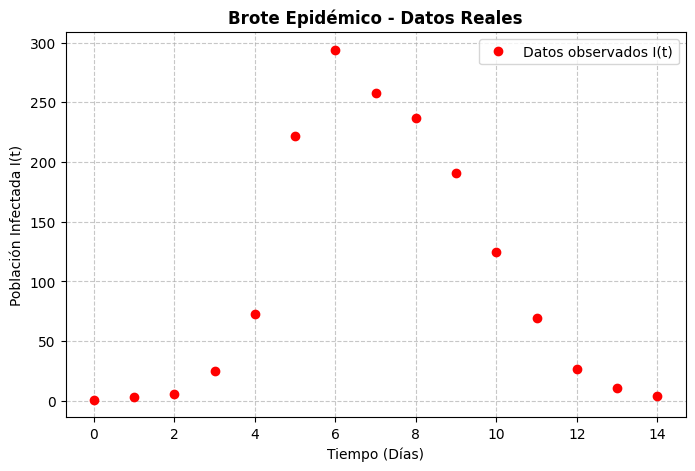

In [8]:
#Mostramos la evolución temporal de los infectados observados durante el brote.
plt.figure(figsize=(8, 5))
plt.plot(t_data, I_data, 'ro', markersize=6, label='Datos observados I(t)')
plt.title('Brote Epidémico - Datos Reales', fontsize=12, fontweight='bold')
plt.xlabel('Tiempo (Días)', fontsize=10)
plt.ylabel('Población Infectada I(t)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 2. Formulación y Solución Numérica del Modelo SIR

Programamos el sistema de EDOs incluyendo explícitamente la división entre la población total $N$, empleando los parámetros $\beta$ (transmisión) y $\gamma$ (recuperación).

In [9]:
# SISTEMA DE EDOs
def sir_model_n(y, t, beta, gamma):
    """ Define el sistema SIR con división por N:
        y: [S, I, R]
    """
    S, I, R = y
    dS_dt = - (beta * S * I) / N
    dI_dt = (beta * S * I) / N - gamma * I
    dR_dt = gamma * I
    return [dS_dt, dI_dt, dR_dt]

def solve_sir_n(beta, gamma, time_points):
    """ Resuelve numéricamente el modelo y retorna la trayectoria de infectados I(t). """
    y0 = [S0, I0, R0]
    sol = odeint(sir_model_n, y0, time_points, args=(beta, gamma))
    return sol[:, 1]  # Retorna la columna de infectados

## 3. Definición de la Función Objetivo (Suma de Errores al Cuadrado / $\chi^2$)

Construimos la función de costo basada en mínimos cuadrados para medir la diferencia entre los infectados estimados por el modelo con parámetros $(\beta, \gamma)$ y los datos reales.

In [10]:
# FUNCIÓN OBJETIVO DE MÍNIMOS CUADRADOS
def chi_squared_n(beta, gamma):
    """Calcula el SSE (Suma de Errores al Cuadrado) para beta y gamma."""
    I_model = solve_sir_n(beta, gamma, t_data)
    return np.sum((I_data - I_model)**2)

## 4. Estimación de Parámetros mediante Metropolis-Hastings (MCMC)

Encontraremos los valores óptimos de $\beta$ y $\gamma$ utilizando el algoritmo MCMC mediante una caminata aleatoria con distribuciones normales propuestas y restricciones de positividad ($\beta > 0, \gamma > 0$).

In [5]:
def metropolis_hastings_n(iters=5000):
    """ Muestrea el espacio de beta, gamma mediante Metropolis-Hastings."""

    # Semillas iniciales aproximadas para beta y gamma
    current_beta, current_gamma = 1.5, 0.4
    current_chi2 = chi_squared_n(current_beta, current_gamma)

    samples = []

    for i in range(iters):
        # Propuesta de nuevos valores
        prop_beta = np.random.normal(current_beta, 0.05)
        prop_gamma = np.random.normal(current_gamma, 0.02)

        # Restricción física: tasas estrictamente positivas
        if prop_beta > 0 and prop_gamma > 0:
            prop_chi2 = chi_squared_n(prop_beta, prop_gamma)

            # Criterio de aceptación Metropolis en escala logarítmica
            log_alpha = -0.5 * (prop_chi2 - current_chi2)

            if np.log(np.random.rand()) < log_alpha:
                current_beta, current_gamma = prop_beta, prop_gamma
                current_chi2 = prop_chi2

        samples.append((current_beta, current_gamma))

    return np.array(samples)

print("Ejecutando Metropolis-Hastings para beta y gamma...")
mh_samples_n = metropolis_hastings_n(iters=5000)

# Obtener los mejores parámetros de la última iteración
best_beta, best_gamma = mh_samples_n[-1]

print(f"\nParámetros optimizados encontrados:")
print(f" - Tasa de transmisión (beta): {best_beta:.4f}")
print(f" - Tasa de recuperación (gamma): {best_gamma:.4f}")

Ejecutando Metropolis-Hastings para beta y gamma...

Parámetros optimizados encontrados:
 - Tasa de transmisión (beta): 1.6645
 - Tasa de recuperación (gamma): 0.4460


## 5. Gráfica y validación del modelo

Graficamos la curva teórica resultante con los parámetros optimizados ($\beta, \gamma$) superpuesta a los datos observados del brote.

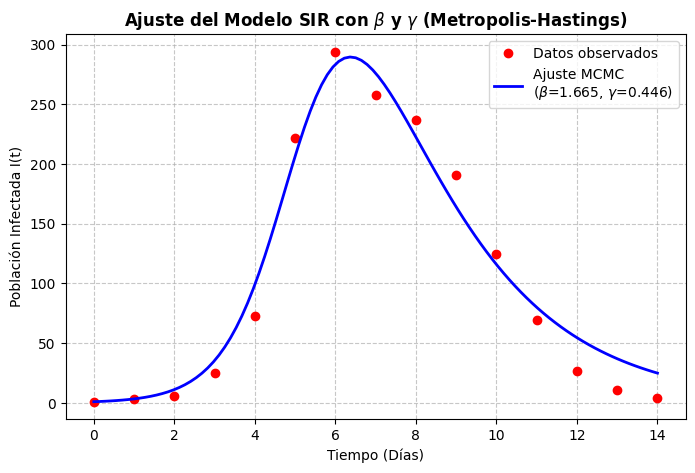

In [6]:
t_smooth = np.linspace(0, 14, 100)
I_fit_n = solve_sir_n(best_beta, best_gamma, t_smooth)

# GRÁFICA DE COMPARACIÓN
plt.figure(figsize=(8, 5))
plt.plot(t_data, I_data, 'ro', markersize=6, label='Datos observados')
plt.plot(
    t_smooth,
    I_fit_n,
    'b-',
    linewidth=2,
    label=f'Ajuste MCMC\n($\\beta$={best_beta:.3f}, $\\gamma$={best_gamma:.3f})'
)
plt.title('Ajuste del Modelo SIR con $\\beta$ y $\\gamma$ (Metropolis-Hastings)', fontsize=12, fontweight='bold')
plt.xlabel('Tiempo (Días)', fontsize=10)
plt.ylabel('Población Infectada I(t)', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()